# 01 — Source datacube and photon budget

**Portfolio / learning project — not a calibrated instrument simulator.** All quantities below are synthetic proxies, literature-derived presets, or engineering estimates (see the [provenance table](../docs/model_details.md#data-provenance)).

This notebook is narrative and self-contained; run the cells top to bottom.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
FIG = pathlib.Path.cwd().parent / 'figures' / 'notebooks'
FIG.mkdir(parents=True, exist_ok=True)


## The datacube `I(x, y, lambda)`
An IFU recovers a spectrum at every point on the sky. We build a *truth* cube of shape `(ny, nx, nlambda)` — a flat continuum plus a Gaussian emission line, with a linear line-of-sight **velocity gradient** that Doppler-shifts the line centre across the field (a toy rotating source).

In [2]:
from ao_fed_ifu.source_cube import (SourceCubeConfig, create_emission_line_cube,
    photon_budget_from_abmag, scale_cube_to_total_electrons)

cfg = SourceCubeConfig(nx=24, ny=24, nlambda=200, lambda_min_um=2.0, lambda_max_um=2.4,
                       exposure_s=600.0, telescope_diameter_m=8.0)
wl = cfg.wavelength_grid_um
centre = 2.2
cube = create_emission_line_cube(cfg, line_center_um=centre, line_flux_rel=8.0,
        line_sigma_um=0.0008, velocity_gradient_kms_per_spaxel=20.0)
print('cube shape (ny, nx, nlambda):', cube.shape)

cube shape (ny, nx, nlambda): (24, 24, 200)


## Photon budget: AB magnitude -> electrons
`photon_budget_from_abmag` converts a source AB magnitude into detected electrons per wavelength bin using the collecting area, exposure time and a scalar throughput (an **engineering estimate**). We use it to put the cube on an absolute electron scale.

In [3]:
e_per_bin = photon_budget_from_abmag(cfg, ab_magnitude=19.0)
total = e_per_bin * cfg.nlambda
cube = scale_cube_to_total_electrons(cube, total)
print(f'electrons/bin = {e_per_bin:.1f}; total electrons = {cube.sum():.3e}')

electrons/bin = 9481.8; total electrons = 1.896e+06


## Line map, velocity field and a sample spectrum

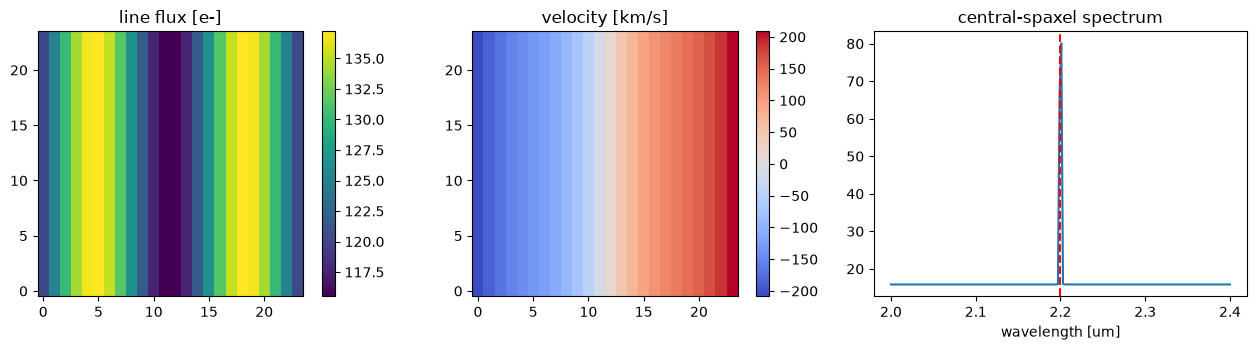

In [4]:
from ao_fed_ifu import diagnostics as diag
window = 0.004
lf = diag.line_flux_map(cube, wl, centre, window)
vel = diag.velocity_centroid_map(cube, wl, centre, window)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
im0 = ax[0].imshow(lf, origin='lower', cmap='viridis'); ax[0].set_title('line flux [e-]')
plt.colorbar(im0, ax=ax[0])
vmax = np.nanmax(np.abs(vel))
im1 = ax[1].imshow(vel, origin='lower', cmap='coolwarm', vmin=-vmax, vmax=vmax)
ax[1].set_title('velocity [km/s]'); plt.colorbar(im1, ax=ax[1])
ax[2].plot(wl, cube[cfg.ny//2, cfg.nx//2, :]); ax[2].axvline(centre, color='r', ls='--')
ax[2].set_title('central-spaxel spectrum'); ax[2].set_xlabel('wavelength [um]')
fig.tight_layout(); fig.savefig(FIG / 'nb01_source_cube.png', dpi=110); plt.show()

In [5]:
summary = pd.DataFrame([{'electrons_per_bin': e_per_bin, 'total_electrons': cube.sum(),
    'velocity_span_kms': float(np.nanmax(vel) - np.nanmin(vel)),
    'line_center_um': centre}])
summary.to_csv(FIG / 'nb01_summary.csv', index=False); summary

,electrons_per_bin,total_electrons,velocity_span_kms,line_center_um
0,9481.767875,1.896354e+06,417.422947,2.2
